# 01 — Quickstart: neural ratio estimation on a toy problem

**Simulation-based inference (SBI)** infers model parameters θ from data x when we can *simulate* data for
any θ, but cannot write down the likelihood p(x | θ). Instead of evaluating a likelihood, we learn from many
simulations.

**Neural ratio estimation (NRE)** trains a classifier on pairs (x, θ):

* *matching* pairs, where x was simulated from θ, and
* *mismatched* pairs, where θ is taken from a different simulation.

A classifier that can tell them apart has learned the ratio r(x, θ) = p(θ | x) / p(θ). Weighting samples
from the prior by r then gives the posterior — for any new observation, in a fraction of a second
(*amortised* inference).

This notebook goes through the full workflow on a toy model:

1. simulate a training grid,
2. split it into training, validation and test sets,
3. define augmentation (noise) and preprocessing (normalisation),
4. choose which parameters to infer and build the network,
5. train and save the run,
6. check the training curves,
7. load the run and compute a posterior,
8. check the results on many test spectra,
9. check that the uncertainties are right (coverage).

In [1]:
from pathlib import Path
import sys
import torch
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if not (ROOT / 'pyproject.toml').is_file():  # Running from notebooks/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from sbi_nre import *

DEVICE = ('cuda' if torch.cuda.is_available()          # NVIDIA GPU
          else 'mps' if torch.backends.mps.is_available()  # Apple silicon GPU
          else 'cpu')
print('Device:', DEVICE)

Device: cuda


## 1. Simulate a training grid

A **grid** is a dictionary of tensors with one entry per simulation: the parameters (shape `[N]`) and the
simulated data (here a spectrum, shape `[N, 100]`). In your own work it comes from your simulator; here we
use a toy model: an absorption line (depth, centre, width) on a sloped continuum. The parameters are drawn
uniformly from the **prior** ranges.

Prior ranges: {'depth': (0.05, 0.5), 'centre': (-0.6, 0.6), 'width': (0.03, 0.2), 'slope': (-0.3, 0.3)}
{'depth': (50000,), 'centre': (50000,), 'width': (50000,), 'slope': (50000,), 'signal': (50000, 100)}


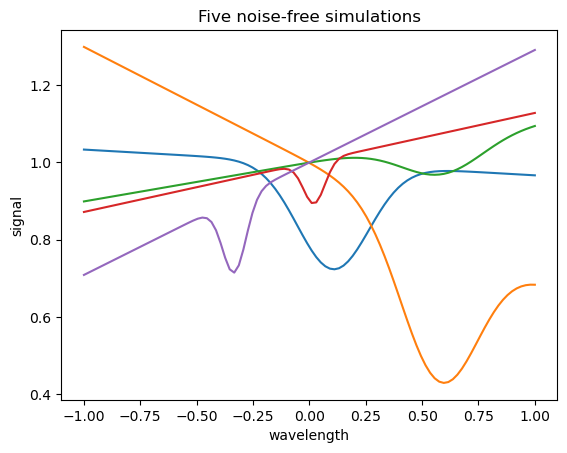

In [2]:
from sbi_nre.toy import PRIOR, simulate_toy, wavelengths

grid = simulate_toy(50_000)
save_grid(grid, ROOT / 'data' / 'toy_grid.pt')
print('Prior ranges:', PRIOR)
print({key: tuple(value.shape) for key, value in grid.items()})

x = wavelengths()
for i in range(5):
    plt.plot(x, grid['signal'][i])
plt.xlabel('wavelength'); plt.ylabel('signal'); plt.title('Five noise-free simulations');

## 2. Load and split the grid

* **training** set: the network learns from it;
* **validation** set: checked after every epoch to detect overfitting and pick the best network;
* **test** set: never used in training; we use it at the end to check the results.

The posterior is obtained by re-weighting **prior samples** (section 7).

In [3]:
grid = load_grid(ROOT / 'data' / 'toy_grid.pt')
training, validation, test = split(grid, (0.8, 0.1, 0.1), seed=0)
print('training', n_samples(training), '| validation', n_samples(validation), '| test', n_samples(test))

training 40000 | validation 5000 | test 5000


## 3. Augmentation and preprocessing

**Augmentation** turns clean simulations into realistic data. Here we add Gaussian noise with a noise level
σ drawn separately for every spectrum (log-uniform between 0.005 and 0.05). It is applied anew to every
training batch, so the network never sees the same noisy spectrum twice.

**Preprocessing** prepares data for the network, for simulations *and* real observations. Here every
spectrum is scaled to 0–1 (`obs_norm`), keeping its minimum and maximum (`obs_min`, `obs_max`).

Steps are written as `step(name, **settings)` so that they can be saved with the run and repeated
exactly when it is loaded.

Keys after preprocessing: ['centre', 'depth', 'obs', 'obs_max', 'obs_min', 'obs_norm', 'sigma', 'signal', 'slope', 'width']


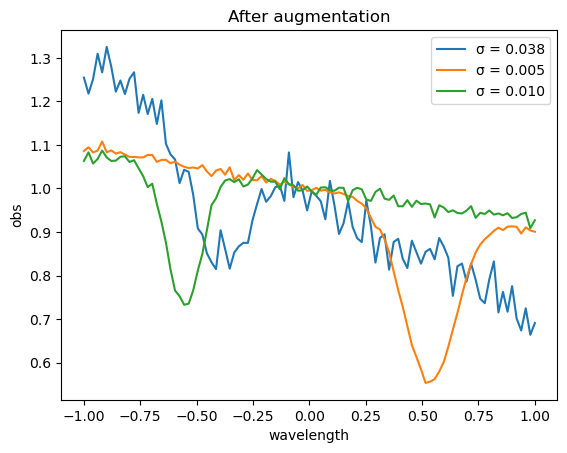

In [4]:
AUGMENT = [step('add_noise', key='signal', out='obs', sigma_key='sigma', sigma_range=[0.005, 0.05])]
PREPROCESS = [step('normalise_minmax', key='obs')]

example = apply(PREPROCESS, apply(AUGMENT, select(training, slice(0, 3))))
for i in range(3):
    plt.plot(x, example['obs'][i], label=f"σ = {example['sigma'][i]:.3f}")
plt.xlabel('wavelength'); plt.ylabel('obs'); plt.legend(); plt.title('After augmentation');
print('Keys after preprocessing:', sorted(example))

## 4. Choose what to infer and build the network

**Parameter groups.** The network learns one posterior per group. A group of two parameters gives their
joint 2D posterior (showing correlations), a group of one gives a 1D posterior. Choose any combination;
every group adds a small classifier.

**Inputs.**
* *observation*: the measured data (here the normalised spectrum and its min/max);
* *context*: other known information about the observation (here the noise level σ). Context tells the
  network, for example, how noisy a spectrum is, so it can make the posterior wider or narrower.

In [5]:
PARAM_GROUPS = [('depth', 'width'), ('centre', 'width'), ('depth', 'slope'), ('centre',)]
OBSERVATION = ['obs_norm', 'obs_min', 'obs_max']
CONTEXT = ['sigma']

model = build_model(example, PARAM_GROUPS, OBSERVATION, CONTEXT, summary_size=64, hidden=[256, 256])
print(model)

RatioEstimator(
  (embedding): Sequential(
    (0): Linear(in_features=103, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=64, bias=True)
  )
  (param_embeddings): ModuleDict()
  (tails): ModuleDict(
    (depth|width): Sequential(
      (0): Linear(in_features=66, out_features=128, bias=True)
      (1): ReLU()
      (2): Linear(in_features=128, out_features=128, bias=True)
      (3): ReLU()
      (4): Linear(in_features=128, out_features=1, bias=True)
    )
    (centre|width): Sequential(
      (0): Linear(in_features=66, out_features=128, bias=True)
      (1): ReLU()
      (2): Linear(in_features=128, out_features=128, bias=True)
      (3): ReLU()
      (4): Linear(in_features=128, out_features=1, bias=True)
    )
    (depth|slope): Sequential(
      (0): Linear(in_features=66, out_features=128, bias=True)
      (1): ReLU()
      (2): Linear(in_features=128, out_fe

## 5. Train

`train` saves everything into the run folder: `config.json` (all settings), `history.json` (losses),
`best.pt` (network with the lowest validation loss) and `last.pt`. It refuses to overwrite an existing
folder, so every run gets a new name (here with the date and time). Training stops early when the validation loss has not improved
for `patience` epochs.

In [6]:
import time

RUN_DIR = ROOT / 'runs' / time.strftime('toy_quickstart_%Y%m%d_%H%M%S')
history = train(model, training, validation, RUN_DIR, augment=AUGMENT, preprocess=PREPROCESS,
                batch_size=256, learning_rate=1e-3, max_epochs=15, patience=5, device=DEVICE,
                notes='Quickstart toy model')

epoch   1  train 0.7813  validation 0.4621  *best  (3.5 s)


epoch   2  train 0.3690  validation 0.3217  *best  (2.4 s)


epoch   3  train 0.2919  validation 0.2935  *best  (2.4 s)


epoch   4  train 0.2708  validation 0.2795  *best  (2.3 s)


epoch   5  train 0.2522  validation 0.2511  *best  (2.4 s)


epoch   6  train 0.2359  validation 0.2712  (2.3 s)


... (5 outputs left out)

epoch  12  train 0.1771  validation 0.1821  *best  (2.3 s)


epoch  13  train 0.1741  validation 0.1839  (1.8 s)


epoch  14  train 0.1723  validation 0.1760  *best  (1.6 s)


epoch  15  train 0.1660  validation 0.1725  *best  (1.5 s)


## 6. Training curves

Both losses should decrease. If the training loss keeps falling while the validation loss rises, the
network is **overfitting**: it memorises the training set instead of learning the general relation.
The right panel shows the validation loss of every parameter group: groups that are harder to constrain
keep a higher loss. The guessing value is 2 ln 2 ≈ 1.39.

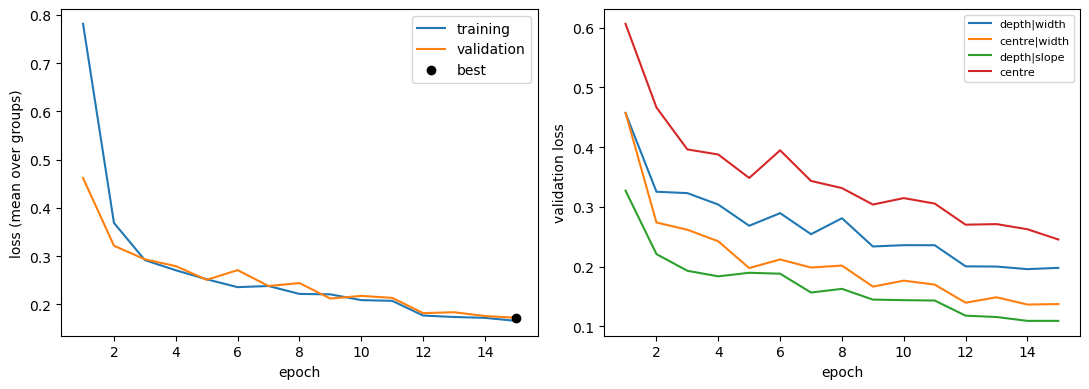

In [7]:
plot_history(history);

## 7. Load the run and compute a posterior

`load_run` rebuilds the network from the run folder — this is all you need later, or on another computer.
We take a test spectrum, add noise (this is our "observation"; for real data you would load it from a
file), and compute the posterior by re-weighting prior samples.

**Prior samples** only need parameter values, no simulations. Our prior is uniform with known ranges, so we
simply draw 200,000 of them. (Without a known prior, use held-out simulations such as the validation set.)
The **effective sample size** tells how many equally weighted samples the posterior is worth; if it is
below a few hundred, the posterior looks noisy and you need more prior samples.

The `+` and dashed lines mark the true parameters, which the posterior should contain.

Effective sample size per group: {'depth|width': 11073, 'centre|width': 4023, 'depth|slope': 2662, 'centre': 9983}


  depth: 0.157 (+0.028 / -0.026)   true 0.179
  width: 0.083 (+0.019 / -0.016)   true 0.078
 centre: 0.161 (+0.017 / -0.017)   true 0.141
  slope: -0.100 (+0.011 / -0.011)   true -0.106


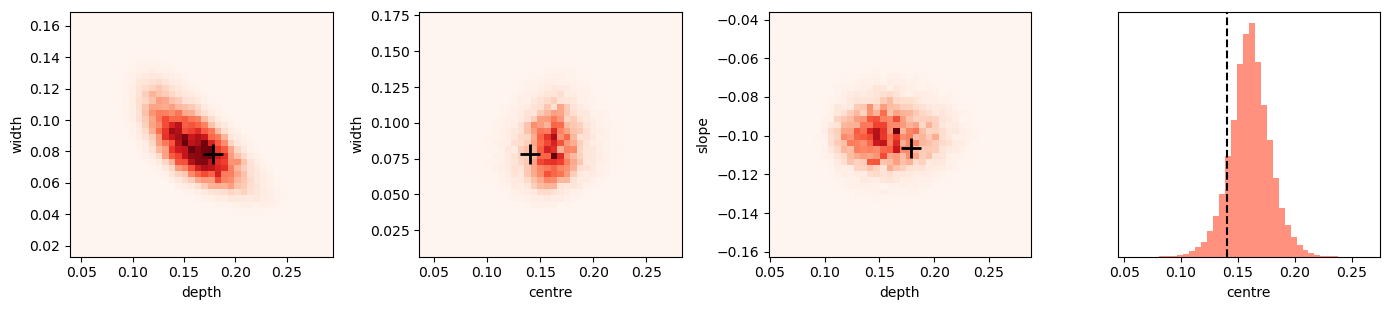

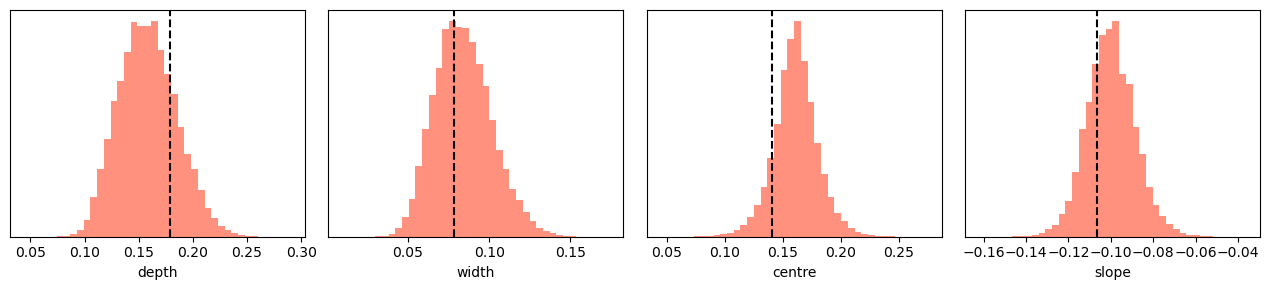

In [8]:
run = load_run(RUN_DIR, device=DEVICE)

torch.manual_seed(30)
observation = select(apply(AUGMENT, select(test, slice(0, 1))), 0)  # One noisy test spectrum.
truths = {p: float(observation[p]) for p in PRIOR}

prior_samples = uniform_prior_samples(PRIOR, 200_000)
result = posterior(run, observation, prior_samples)
print('Effective sample size per group:', {name: round(effective_sample_size(g['weights'])) for name, g in result.items()})
plot_posterior(result, truths);
plot_marginals(result, truths);
for p, (low, median, high) in summarise(result).items():
    print(f'{p:>7}: {median:.3f} (+{high - median:.3f} / -{median - low:.3f})   true {truths[p]:.3f}')
save_posterior(result, RUN_DIR / 'posterior_test0.npz')

## 8. Does it work on many spectra?

For 300 test spectra we compare the posterior median with the true value. Points on the diagonal are
perfect recoveries; the scatter shows the typical uncertainty. Parameters the data barely constrain show a
flat cloud.

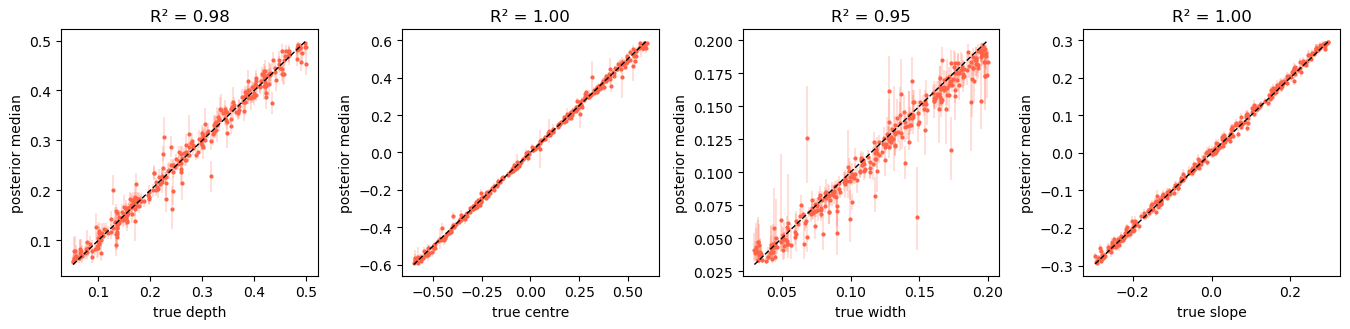

In [9]:
medians, truths, errors = {p: [] for p in PRIOR}, {p: [] for p in PRIOR}, {p: ([], []) for p in PRIOR}
torch.manual_seed(2)
noisy_test = apply(AUGMENT, select(test, slice(0, 300)))
for i in range(300):
    summary = summarise(posterior(run, select(noisy_test, i), prior_samples))
    for p in PRIOR:
        low, median, high = summary[p]
        medians[p].append(median); truths[p].append(float(noisy_test[p][i]))
        errors[p][0].append(low); errors[p][1].append(high)
plot_true_vs_median(truths, medians, errors=errors);

## 9. Are the uncertainties right? (coverage)

A posterior can have the right median but be too narrow or too wide. **Coverage** checks this. For a 68%
credible region, the true parameters should lie inside it for 68% of test spectra; for 95%, in 95%; and so on
for every level.

For each test spectrum we find the *credibility level of the truth*: the posterior mass of all prior samples
the network finds more probable than the true parameters. The plot shows, for every level α, the fraction of
test spectra whose truth lies inside the α credible region:

* on the **diagonal**: well calibrated (the grey band is the scatter expected from a finite test set);
* **above**: posteriors too wide (conservative: safe, but you lose precision);
* **below**: posteriors too narrow (overconfident: the dangerous case).

This also explains the single spectrum in section 7: even for a perfect network, about one truth in three lies
outside its 68% region.

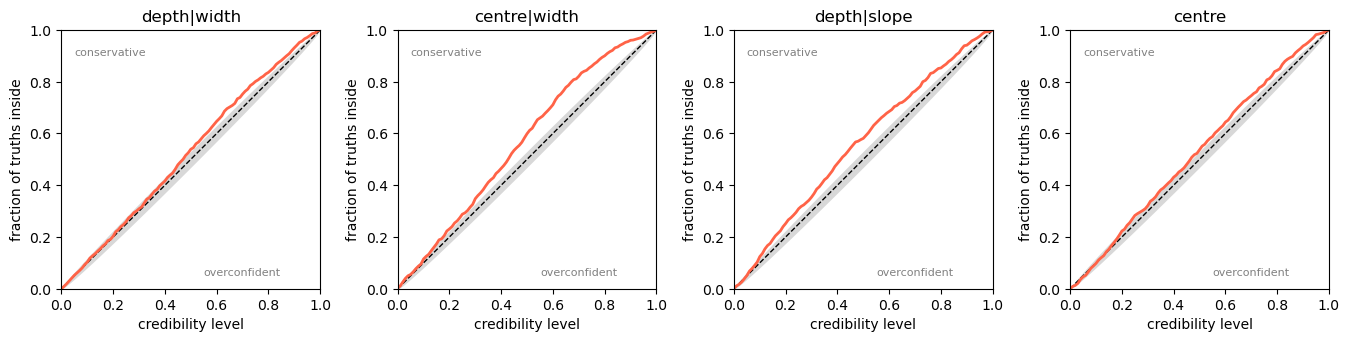

In [10]:
N_COVERAGE = 1000  # More test spectra give a smoother curve (but take longer).
torch.manual_seed(3)
coverage_test = apply(AUGMENT, select(test, slice(0, N_COVERAGE)))
levels = credibility_of_truth(run, coverage_test, prior_samples)
plot_coverage(levels);

## Next steps

* `02_joint_posterior_mcmc.ipynb` learns the joint posterior of all four parameters with one group and samples
  it with MCMC, and explains why the marginal groups here could skip that step.
* `03_your_own_grid.ipynb` is a template for your own simulations: set the file, parameters and inputs in
  one cell and run it.
* Try changing the parameter groups, the noise range or the network size, and compare the training curves.